In [1]:
import torch 
import torch.nn.functional as F
import matplotlib.pyplot as plt 
%matplotlib inline 

In [2]:
words = open('names.txt', 'r').read().splitlines()
words[:8]

['emma', 'olivia', 'ava', 'isabella', 'sophia', 'charlotte', 'mia', 'amelia']

In [3]:
len(words)

32033

In [20]:
chars = sorted(list(set(''.join(words))))
stoi = {s:i+1 for i,s in enumerate(chars)}
stoi['.'] = 0 
itos = {i:s for s,i in stoi.items()}


In [73]:
# Build a dataset of a list of X and Y with a build_context of 3 

block_size = 3
X, Y = [], [] 

for w in words: 
    context = [0] * block_size
    for ch in w + '.': 
        ix = stoi[ch] 
        X.append(context) 
        Y.append(ix) 
        context = context[1:] + [ix] 
X = torch.tensor(X) 
Y = torch.tensor(Y) 

In [23]:
# BUILD A NEURAL NETWORK THAT TKAES XS AND BUILDS YS 
# BUILD AN EMBEDDING LOOK UP TABLE C 

# In the Word-level LM - the 17,000 words were embedded in a 30-dim vector 
# Here, 27 possible characters 

C = torch.randn((27, 2)) 
C[5]

tensor([0.0727, 0.0413])

In [27]:
X.dtype, X.shape, Y.dtype, Y.shape 

(torch.int64, torch.Size([32, 3]), torch.int64, torch.Size([32]))

In [51]:
emb = C[X]
emb.shape # [a,b] = C => [1,2] 
# Basically if u want to index the logits of each characters, you use the 32 inputs that are composed of 3 sections 

torch.Size([32, 3, 2])

In [48]:
w1 = torch.randn((6,100)) 
b1 = torch.randn(100)  

In [50]:
# Hidden tanh h layer, task 2 randn values per 3 inputs from context, apply weights on 6 inputs (100x as per neurons)
# transform the [32, 3, 2], matrix manipulation is [32, 6] such that products are same
h = torch.tanh(emb.view(32, 6) @ w1 + b1)
h.shape

torch.Size([32, 100])

In [46]:
# NOTES ---------
"""
torch.cat([emb[:, 0, :], emb[:, 1, :], emb[:, 2, :]], 1).shape
# Now you have concatenated three [32,2] vectors 

# instead of manaully assigning the index for your inputs that you want to retreive 
# torch.unbind essentially essentially does the same thing
torch.cat(torch.unbind(emb, 1), 1).shape
# currently this is inefficient and creates new memeory 
"""

'\ntorch.cat([emb[:, 0, :], emb[:, 1, :], emb[:, 2, :]], 1).shape\n# Now you have concatenated three [32,2] vectors \n\n# instead of manaully assigning the index for your inputs that you want to retreive \n# torch.unbind essentially essentially does the same thing\ntorch.cat(torch.unbind(emb, 1), 1).shape\n# currently this is inefficient and creates new memeory \n'

In [52]:
# now boss, it doesnt make sense to have 100 logits for the 2-set probabilities of 27 characters
W2 = torch.randn((100, 27)) 
b2 = torch.randn(27)

In [53]:
logits = h @ W2 + b2

In [54]:
logits.shape

torch.Size([32, 27])

In [58]:
counts = logits.exp() 
prob = counts / counts.sum(1, keepdims=True)
prob[0].sum()

tensor(1.)

In [60]:
loss = -prob[torch.arange(32), Y].log().mean() 
loss

tensor(17.9076)

In [177]:
# Build a dataset of a list of X and Y with a build_context of 3 

def build_dataset(words): 
    block_size = 3
    X, Y = [], [] 
    
    for w in words: 
        context = [0] * block_size
        for ch in w + '.': 
            ix = stoi[ch] 
            X.append(context) 
            Y.append(ix) 
            context = context[1:] + [ix] 
            
    X = torch.tensor(X) 
    Y = torch.tensor(Y) 
    print(X.shape, Y.shape) 
    return X, Y

import random 
random.seed(42) 
random.shuffle(words)
n1 = int(0.8 * len(words)) 
n2 = int(0.9 * len(words)) 

Xtr, Ytr = build_dataset(words[:n1]) 
Xdev, Ydev = build_dataset(words[n1:n2]) 
Xte, Yte = build_dataset(words[n2:]) 

torch.Size([182437, 3]) torch.Size([182437])
torch.Size([22781, 3]) torch.Size([22781])
torch.Size([22928, 3]) torch.Size([22928])


In [178]:
# --- Now time to make more respectable --------
X.shape, Y.shape

(torch.Size([228146, 3]), torch.Size([228146]))

In [213]:
g = torch.Generator().manual_seed(2147483647)
C = torch.randn((27,10), generator=g) 
W1 = torch.randn((30,200), generator=g) 
b1 = torch.randn(200, generator=g) 
W2 = torch.randn((200,27), generator=g) 
b2 = torch.randn(27, generator=g) 
parameters= [C, W1, W2, b1, b2] 


In [214]:
sum(p.nelement() for p in parameters)

11897

In [216]:
for p in parameters: 
    p.requires_grad = True 

In [217]:
lri = [] 
lossi = []
stepi = [] 

In [234]:
for i in range(100000): 

    # minibatch 
    ix = torch.randint(0, Xtr.shape[0], (32,))
    # forward pass 
    emb = C[Xtr[ix]]
    h = torch.tanh(emb.view(-1,30) @ W1 + b1) 
    logits = h @ W2 + b2 # 32, 27 
    
    # Classification where logits shows loss (softmax activation function is unc status now) 
    loss = F.cross_entropy(logits, Ytr[ix])
    #backward pass 
    for p in parameters: 
        p.grad = None # zero reset  
    loss.backward() 
    
    # update 
    lr = 0.1 if i < 50000 else 0.01
    for p in parameters: 
        p.data += -lr * p.grad

    # track stats 
    #lri.append(lre[i]) 
    stepi.append(i)
    lossi.append(loss.log10().item()) 

# Fix the slow ouput issue 


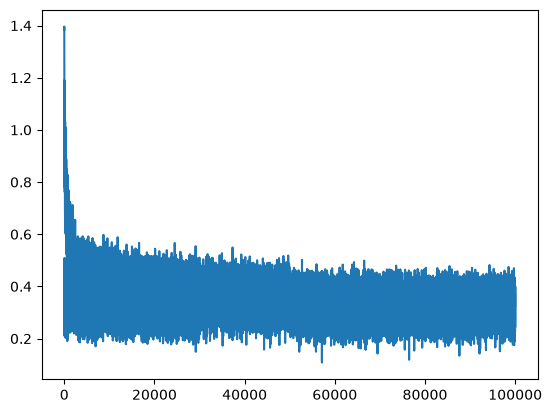

In [235]:
plt.plot(stepi, lossi) 

In [236]:
emb = C[Xdev] 
h = torch.tanh(emb.view(-1,30) @ W1 + b1) 
logits = h @ W2 + b2 # 32, 27 
loss = F.cross_entropy(logits, Ydev)
loss

tensor(2.1895, grad_fn=<NllLossBackward0>)

In [ ]:
# Classification via softmax activation is not numerically strong for very positive/negative nums (u can get out of range) 

# Multi-Step Improvements: 
# 1. Mini Batches for speed
# 2. Calculate the best learning rate
# 3. training split, dev/validation split (train hyper perameters), test split (evaluate loss) 
# 4. Investigating potential bottlenecks: 
    # a. increased parameters (in the hidden layers) 
    # b. increase vector embedded for each character
# train the neural network on only 80% dataset

# Scrutinize which experiment give best dev perforemcne, take those hyperparameters and test against test once, and you use that in a research paper

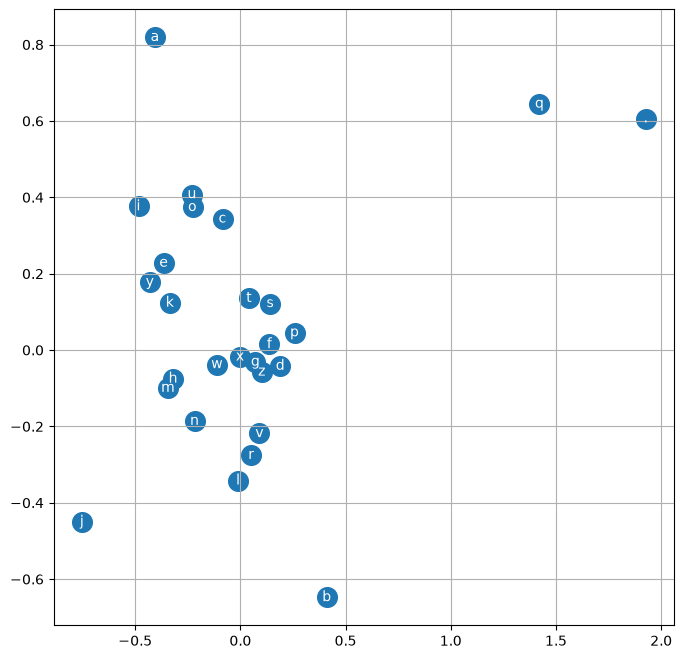

In [229]:
plt.figure(figsize=(8,8))
plt.scatter(C[:,0].data, C[:,1].data, s=200) 
for i in range(C.shape[0]): 
    plt.text(C[i,0].item(), C[i,1].item(), itos[i], ha="center", va="center", color="white") 
plt.grid("minor")

In [ ]:
"""

#### HOMEWORK: READ PAPER 





"""